In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
import os
import sys
from pathlib import Path

# Run from repo root. If you're elsewhere, uncomment and set this.
# os.chdir("/path/to/movebench")

# IMPORTANT: movebench uses MOVEBENCH_DATA_ROOT to find studies.
# If unset, it defaults to <repo>/data/movebench.
# os.environ["MOVEBENCH_DATA_ROOT"] = "/absolute/path/to/movebench_data"

repo_root = Path.cwd().resolve()
sys.path.insert(0, str(repo_root))

print("repo_root:", repo_root)
print("MOVEBENCH_DATA_ROOT:", os.environ.get("MOVEBENCH_DATA_ROOT"))


repo_root: /Users/justinkay/movebench
MOVEBENCH_DATA_ROOT: None


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from movebench import Study


In [4]:
# Study to inspect
study_id = "tsavo_lions"
config_path = "configs/layers_local.yaml"  # try: "configs/layers_all.yaml"
split = "train"  # or "test"
idx = 0  # dataset index within the split

study = Study(study_id)
plan = study.layer_plan(config_path)

print("study_dir:", study.study_dir)
print("trajectories_path:", study.trajectories_path)
print("config_hash:", plan.config_hash)
print("layers:", len(plan.layers_in_order))
print("channels:", plan.num_channels())
print("derived:", sorted(plan.derived_dependencies.keys()))


study_dir: /Users/justinkay/movebench/data/movebench/studies/tsavo_lions
trajectories_path: /Users/justinkay/movebench/data/movebench/studies/tsavo_lions/trajectories.csv
config_hash: dc5e291c4989ce94
layers: 16
channels: 53
derived: ['aspect', 'orographic_uplift_hourly', 'rugosity', 'slope', 'thermal_uplift_hourly']


In [ ]:
# Create an SSFDataset. This requires that the corresponding point features have been extracted.
# If you haven't extracted yet, run (once):
# study.extract_point_features(config=config_path, splits=[split], parametric=False, n_workers=1)
ds = study.ssf_dataset(split=split, config=config_path, normalize=False)

print("len(ds):", len(ds))
print("store_dir:", ds.store_dir)
print("sampler:", ds.manifest.sampler)
print("extraction:", ds.manifest.extraction)


In [ ]:
env, valid, extra, crs = ds[idx]
band_ids = ds.plan.band_ids_in_order()

print("env:", tuple(env.shape), env.dtype)
print("valid:", tuple(valid.shape), valid.dtype)
print("crs:", crs)
assert env.shape == valid.shape
assert env.shape[0] == ds.plan.num_channels()

P = int(env.shape[1])
print("P candidates (last index is true):", P, "true_idx=", P - 1)

# Invariants: env is materialized to 0.0 where valid=False, and env is finite everywhere.
max_abs_invalid = env[~valid].abs().max().item() if (~valid).any() else 0.0
finite_frac = torch.isfinite(env).float().mean().item()
print("max_abs_invalid:", max_abs_invalid)
print("finite_frac:", finite_frac)

if ds.step_length_m is not None:
    sl = ds.step_length_m[idx]
    print("step_length_m (P,):", tuple(sl.shape), "true=", float(sl[-1].item()))
if ds.turn_angle_rad is not None:
    ta = ds.turn_angle_rad[idx]
    print("turn_angle_rad (P,):", tuple(ta.shape), "true=", float(ta[-1].item()))


In [7]:
band_to_idx = {b: i for i, b in enumerate(band_ids)}
print("example band ids:")
for b in band_ids[:20]:
    print(" ", b)


example band ids:
  modis_lst.LST_Day_1km
  modis_lst.LST_Night_1km
  modis_vi.NDVI
  modis_vi.EVI
  modis_ndsi.NDSI
  modis_bai.BAI
  era5_land_hourly.temperature_2m
  era5_land_hourly.dewpoint_temperature_2m
  era5_land_hourly.total_precipitation
  era5_land_hourly.surface_pressure
  era5_land_hourly.u_component_of_wind_10m
  era5_land_hourly.v_component_of_wind_10m
  era5_land_hourly.surface_solar_radiation_downwards
  era5_land_hourly.surface_thermal_radiation_downwards
  era5_land_hourly.surface_net_solar_radiation
  era5_land_hourly.surface_net_thermal_radiation
  era5_land_hourly.surface_latent_heat_flux
  era5_land_hourly.surface_sensible_heat_flux
  era5_land_hourly.snow_depth
  era5_hourly.boundary_layer_height


In [8]:
def plot_band(band_id: str):
    if band_id not in band_to_idx:
        print(f"skip (missing): {band_id}")
        return
    i = band_to_idx[band_id]
    x = env[i].detach().cpu().numpy()
    m = valid[i].detach().cpu().numpy().astype(bool)
    xs = np.arange(x.shape[0])

    fig, ax = plt.subplots(1, 1, figsize=(7, 3))
    ax.plot(xs[m], x[m], "o", ms=4, label="valid")
    if (~m).any():
        ax.plot(xs[~m], x[~m], "x", ms=4, label="invalid")
    ax.axvline(x.shape[0] - 1, color="k", lw=1, alpha=0.4)
    ax.set_title(f"{band_id} (candidate values)")
    ax.set_xlabel("candidate index (last is true)")
    ax.set_ylabel("value")
    ax.legend(loc="best")
    plt.show()


def plot_layer(layer: str, *, max_bands=12, ncols=3):
    if layer not in ds.plan.layers_in_order:
        print(f"skip (missing layer): {layer}")
        return
    start, end = ds.plan.layer_slice(layer)
    ids = band_ids[start:end][:max_bands]
    ncols = min(ncols, len(ids))
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows), squeeze=False)
    axes = axes.reshape(-1)
    for j, ax in enumerate(axes):
        if j >= len(ids):
            ax.axis("off")
            continue
        bid = ids[j]
        i = band_to_idx[bid]
        x = env[i].detach().cpu().numpy()
        m = valid[i].detach().cpu().numpy().astype(bool)
        xs = np.arange(x.shape[0])
        ax.plot(xs[m], x[m], "o", ms=3)
        if (~m).any():
            ax.plot(xs[~m], x[~m], "x", ms=3)
        ax.axvline(x.shape[0] - 1, color="k", lw=1, alpha=0.3)
        ax.set_title(bid)
        ax.set_xlabel("cand")
    fig.suptitle(layer)
    plt.tight_layout()
    plt.show()


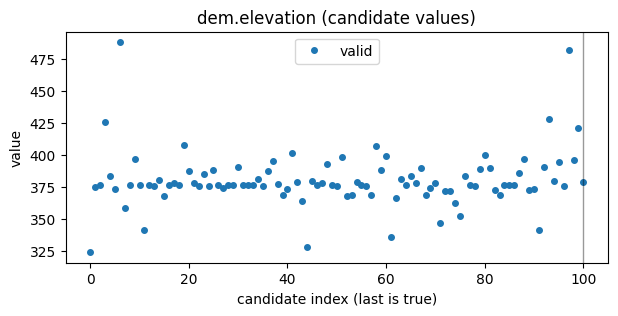

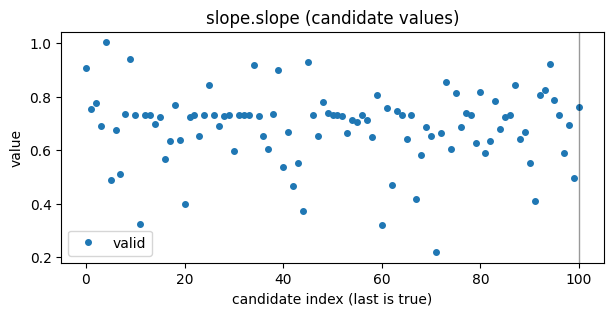

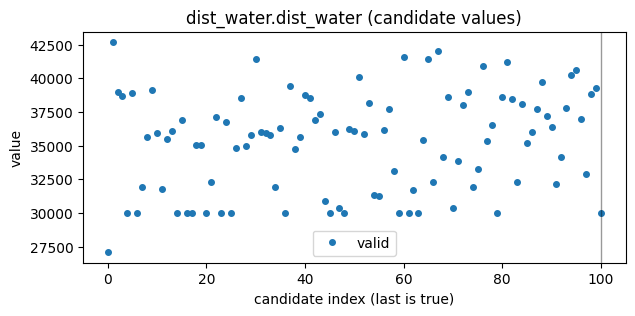

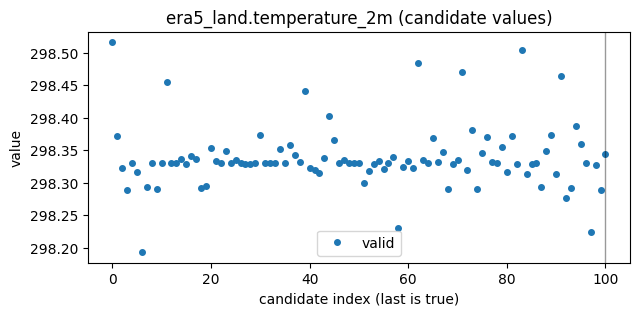

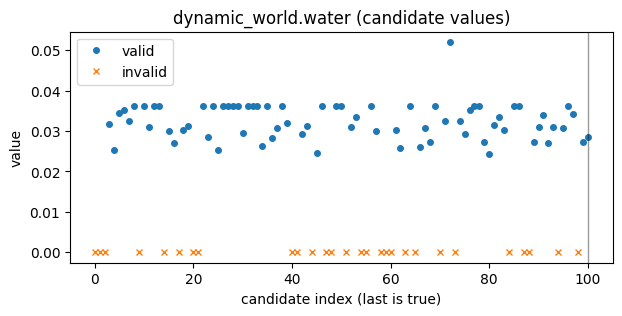

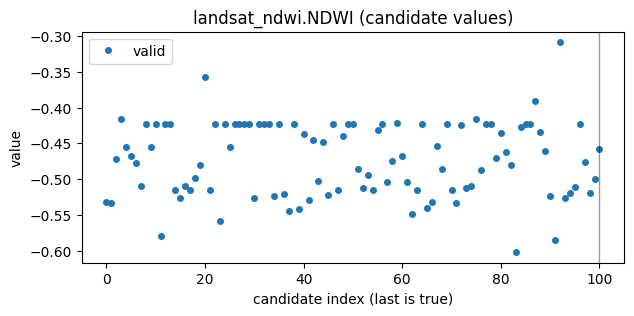

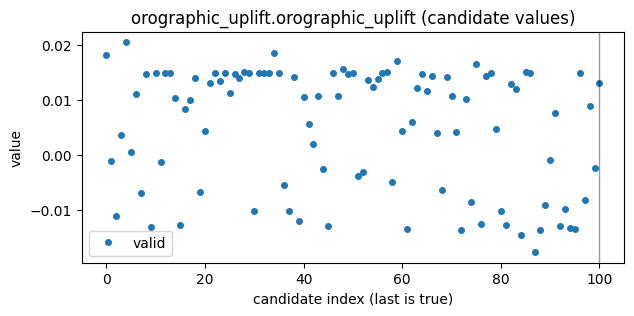

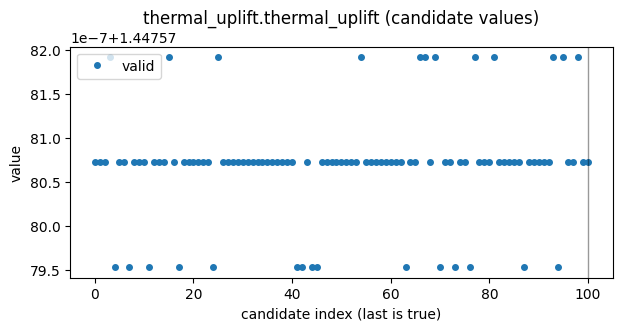

In [9]:
# Plot a few representative bands (skips if not present in this config).
bands_to_plot = [
    "dem.elevation",
    "slope.slope",
    "dist_water.dist_water",
    "era5_land_hourly.temperature_2m",
    "dynamic_world.water",
    "landsat_ndwi.NDWI",
    "orographic_uplift_hourly.orographic_uplift_hourly",
    "thermal_uplift_hourly.thermal_uplift_hourly",
]

for b in bands_to_plot:
    plot_band(b)


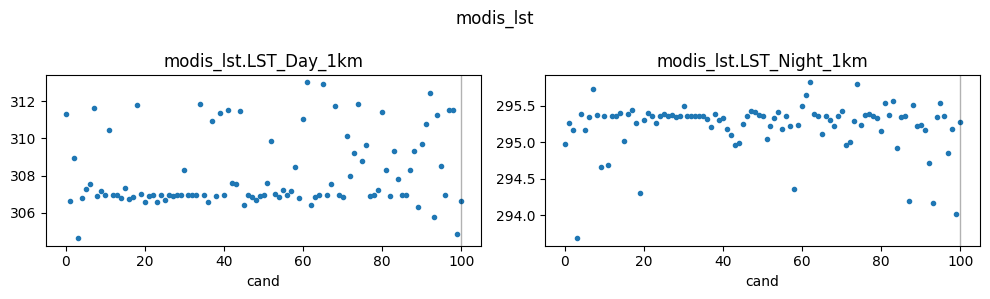

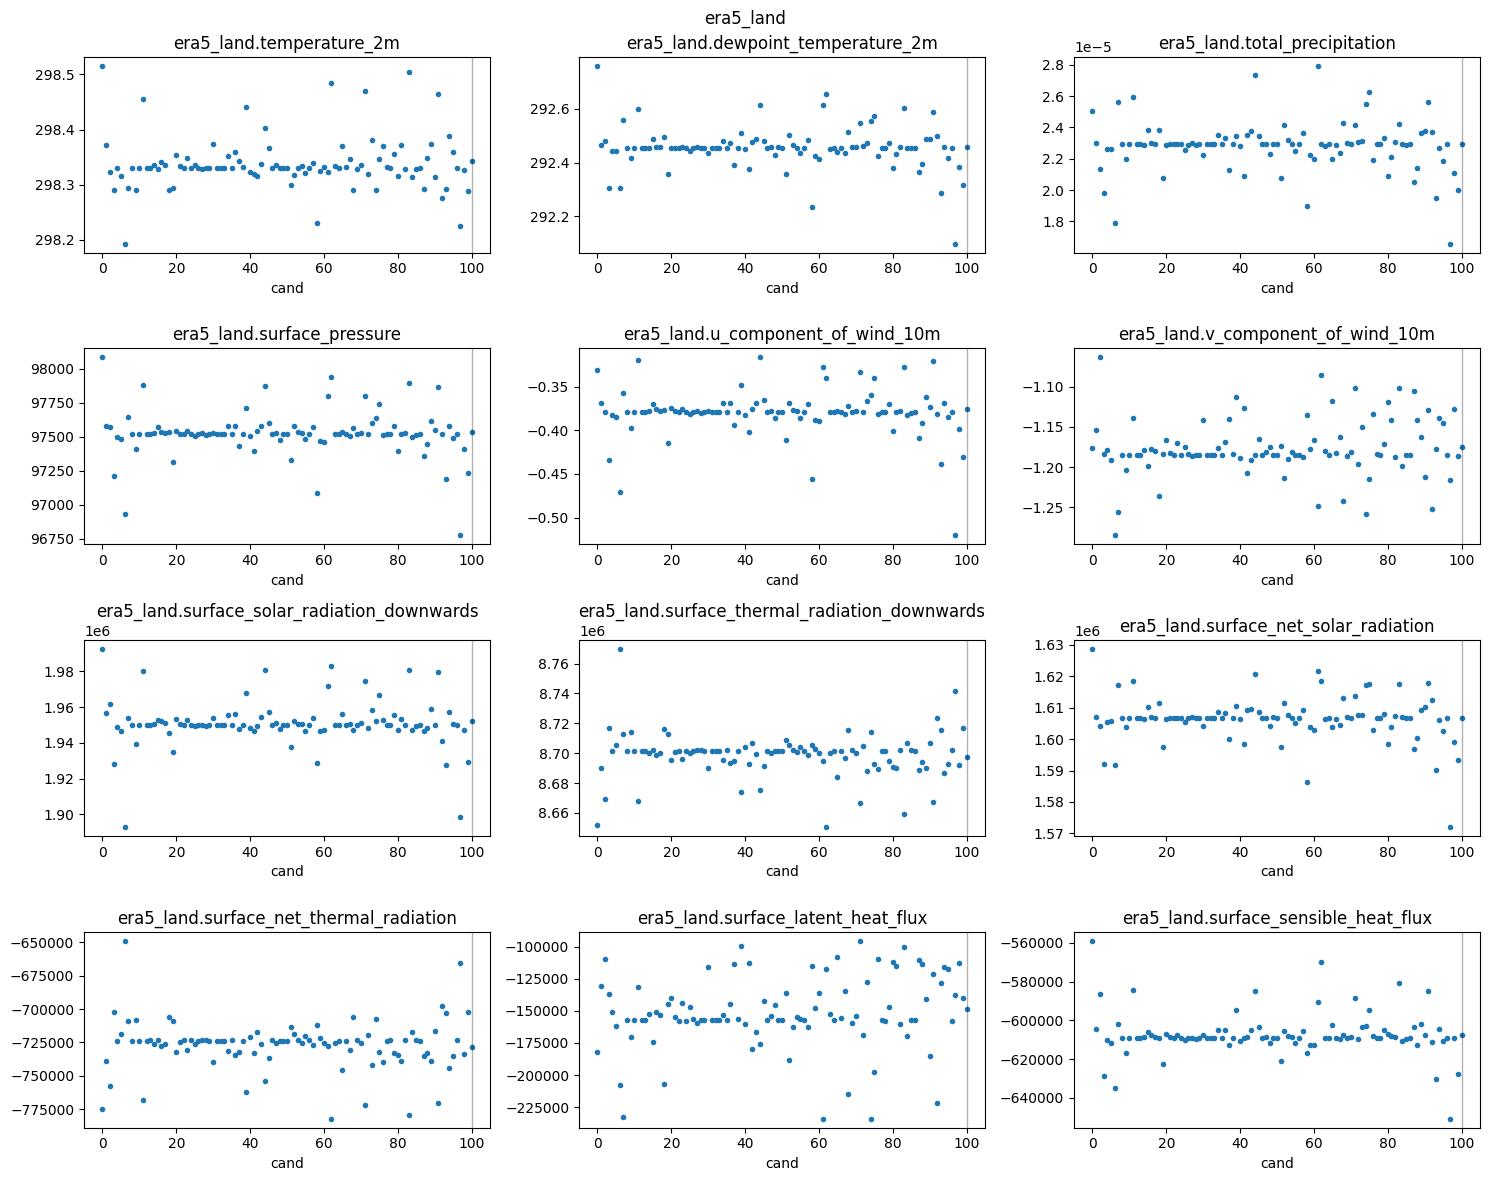

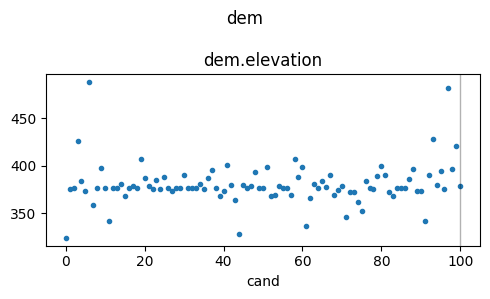

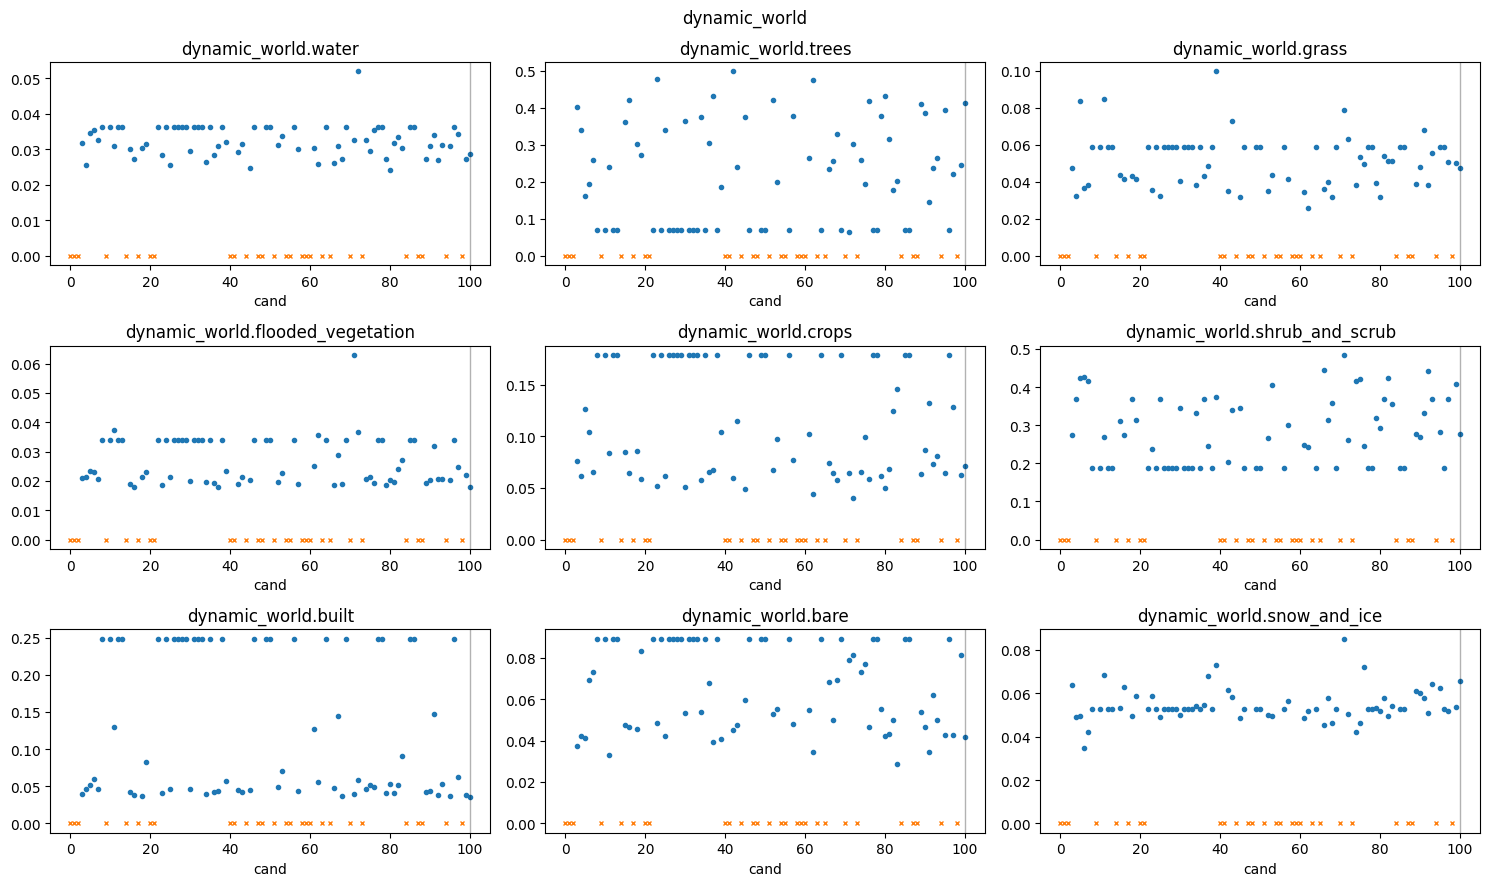

In [10]:
# Plot entire layers (first N bands).
for layer in ["modis_lst", "era5_land_hourly", "dem", "dynamic_world"]:
    plot_layer(layer)


In [11]:
# If modis_lc is present: check one-hot property across candidates.
if "modis_lc" in ds.plan.layers_in_order:
    s, e = ds.plan.layer_slice("modis_lc")
    lc_env = env[s:e]
    lc_valid = valid[s:e]
    lc_any_valid = lc_valid.any(dim=0)
    lc_sum = lc_env.sum(dim=0)
    max_err_valid = (lc_sum[lc_any_valid] - 1.0).abs().max().item() if lc_any_valid.any() else 0.0
    max_sum_invalid = lc_sum[~lc_any_valid].abs().max().item() if (~lc_any_valid).any() else 0.0
    print("modis_lc max |sum-1| on valid candidates:", max_err_valid)
    print("modis_lc max |sum| on invalid candidates:", max_sum_invalid)

# If dynamic_world is present: check one-hot property (prob channels sum to ~1).
if "dynamic_world" in ds.plan.layers_in_order:
    s, e = ds.plan.layer_slice("dynamic_world")
    dw_env = env[s:e]
    dw_valid = valid[s:e]
    dw_any_valid = dw_valid.any(dim=0)
    dw_sum = dw_env.sum(dim=0)
    max_err_valid = (dw_sum[dw_any_valid] - 1.0).abs().max().item() if dw_any_valid.any() else 0.0
    max_sum_invalid = dw_sum[~dw_any_valid].abs().max().item() if (~dw_any_valid).any() else 0.0
    print("dynamic_world max |sum-1| on valid candidates:", max_err_valid)
    print("dynamic_world max |sum| on invalid candidates:", max_sum_invalid)


dynamic_world max |sum-1| on valid candidates: 0.06911498308181763
dynamic_world max |sum| on invalid candidates: 0.0


In [12]:
# Optional: iSSF dataset (parametric sampling). Requires parametric point features:
# study.extract_point_features(config=config_path, splits=[split], parametric=True, n_workers=1)
# ds_issf = study.issf_dataset(split=split, config=config_path, include_time=True, normalize=False)
# x, v, _, _ = ds_issf[idx]
# print('iSSF x:', tuple(x.shape), x.dtype)
# print('iSSF valid:', tuple(v.shape), v.dtype)


In [13]:
# Optional: verify env normalization (requires normalization stats):
# study.compute_normalization_vals(from_='points', config=config_path)
# ds_norm = study.ssf_dataset(split=split, config=config_path, normalize=True)
# env_n, valid_n, _, _ = ds_norm[idx]
# print('env_norm:', tuple(env_n.shape), env_n.dtype)
# print('mean(valid):', float(env_n[valid_n].mean().item()))
# print('std(valid):', float(env_n[valid_n].std(unbiased=False).item()))
